In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [2]:
df_train_data = pd.read_csv("train_data.csv")
df_test_data = pd.read_csv("test_data.csv")

# ESTUDIO PREVIO DE TODA LA TABLA

In [3]:
df_train_data

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,patientid,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911.0,0-10
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954.0,41-50
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745.0,31-40
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272.0,41-50
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558.0,41-50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318433,318434,6,a,6,X,3,radiotherapy,Q,F,4.0,86499,23.0,Emergency,Moderate,3,41-50,4144.0,11-20
318434,318435,24,a,1,X,2,anesthesia,Q,E,4.0,325,8.0,Urgent,Moderate,4,81-90,6699.0,31-40
318435,318436,7,a,4,X,3,gynecology,R,F,4.0,125235,10.0,Emergency,Minor,3,71-80,4235.0,11-20
318436,318437,11,b,2,Y,3,anesthesia,Q,D,3.0,91081,8.0,Trauma,Minor,5,11-20,3761.0,11-20


## NULOS Y VALORES ÚNICOS

In [4]:
(df_train_data.isna().sum()/df_train_data.shape[0]*100).round(2)

case_id                              0.00
Hospital_code                        0.00
Hospital_type_code                   0.00
City_Code_Hospital                   0.00
Hospital_region_code                 0.00
Available Extra Rooms in Hospital    0.00
Department                           0.00
Ward_Type                            0.00
Ward_Facility_Code                   0.00
Bed Grade                            0.04
patientid                            0.00
City_Code_Patient                    1.42
Type of Admission                    0.00
Severity of Illness                  0.00
Visitors with Patient                0.00
Age                                  0.00
Admission_Deposit                    0.00
Stay                                 0.00
dtype: float64

In [5]:
df_train_data.nunique()

case_id                              318438
Hospital_code                            32
Hospital_type_code                        7
City_Code_Hospital                       11
Hospital_region_code                      3
Available Extra Rooms in Hospital        18
Department                                5
Ward_Type                                 6
Ward_Facility_Code                        6
Bed Grade                                 4
patientid                             92017
City_Code_Patient                        37
Type of Admission                         3
Severity of Illness                       3
Visitors with Patient                    28
Age                                      10
Admission_Deposit                      7300
Stay                                     11
dtype: int64

In [6]:
df_train_data.shape

(318438, 18)

## ESTUDIO COLUMNAS

In [7]:
df_train_data.groupby(["Hospital_region_code", "City_Code_Hospital"]).size()

Hospital_region_code  City_Code_Hospital
X                     1                     55351
                      4                     13857
                      6                     46991
                      11                    17137
Y                     2                     51809
                      7                     35463
                      9                     26277
                      10                     5249
                      13                     3630
Z                     3                     31569
                      5                     31105
dtype: int64

In [8]:
df_train_data.groupby(["Department"]).size()

Department
TB & Chest disease      9586
anesthesia             29649
gynecology            249486
radiotherapy           28516
surgery                 1201
dtype: int64

In [26]:
df_train_data.groupby(["Ward_Type"]).size()

Ward_Type
P      5046
Q    106165
R    127947
S     77794
T      1477
U         9
dtype: int64

In [10]:
df_train_data.groupby(["Ward_Facility_Code"]).size()

Ward_Facility_Code
A     27906
B     35156
C     35463
D     51809
E     55351
F    112753
dtype: int64

In [11]:
df_train_data.groupby(["Bed Grade"]).size()

Bed Grade
1.0     26505
2.0    123671
3.0    110583
4.0     57566
dtype: int64

In [12]:
df_train_data.groupby(["Type of Admission"]).size()

Type of Admission
Emergency    117676
Trauma       152261
Urgent        48501
dtype: int64

In [13]:
df_train_data.groupby(["Severity of Illness"]).size()

Severity of Illness
Extreme      56723
Minor        85872
Moderate    175843
dtype: int64

In [14]:
df_train_data.groupby(["Visitors with Patient"]).size()

Visitors with Patient
0         22
1       1207
2     138417
3      59180
4      79225
5       9219
6      18860
7       2504
8       4872
9       1358
10      1183
11       327
12       968
13       106
14       207
15       194
16       286
17        20
18        61
19        12
20        62
21        11
22        19
23        10
24        78
25        12
30         9
32         9
dtype: int64

In [15]:
df_train_data.groupby(["Age"]).size()

Age
0-10       6254
11-20     16768
21-30     40843
31-40     63639
41-50     63749
51-60     48514
61-70     33687
71-80     35792
81-90      7890
91-100     1302
dtype: int64

In [16]:
df_train_data.groupby(["Stay"]).size()

Stay
0-10                  23604
11-20                 78139
21-30                 87491
31-40                 55159
41-50                 11743
51-60                 35018
61-70                  2744
71-80                 10254
81-90                  4838
91-100                 2765
More than 100 Days     6683
dtype: int64

In [47]:
df_train_data["Admission_Deposit"].describe()

count    318438.000000
mean       4880.749392
std        1086.776254
min        1800.000000
25%        4186.000000
50%        4741.000000
75%        5409.000000
max       11008.000000
Name: Admission_Deposit, dtype: float64

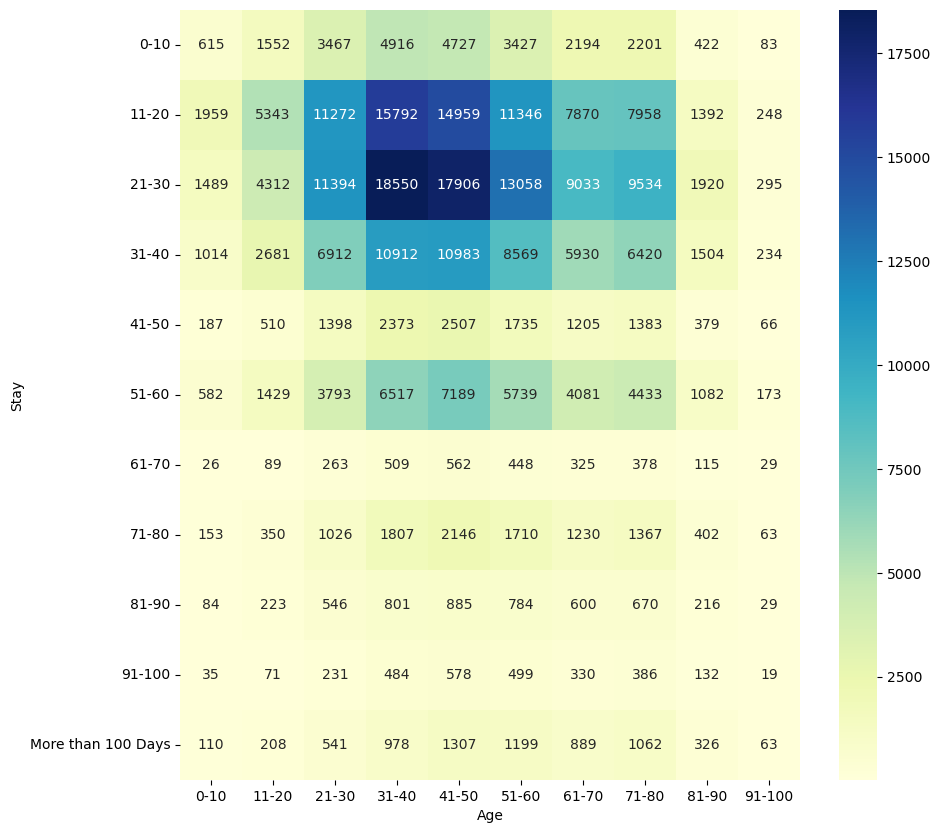

In [39]:
freq = pd.crosstab(df_train_data['Stay'], df_train_data['Age'])

plt.figure(figsize = (10,10))
sns.heatmap(freq, annot=True, fmt="d", cmap="YlGnBu")
plt.xlabel('Age')
plt.ylabel('Stay')
plt.show()

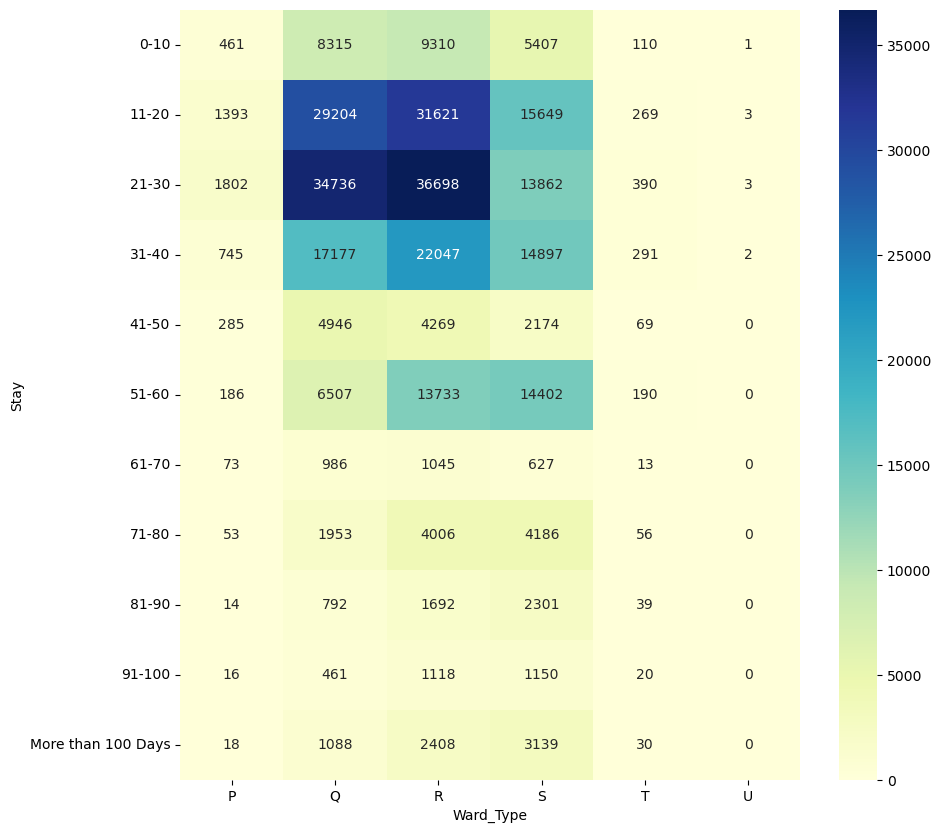

In [18]:
freq = pd.crosstab(df_train_data['Stay'], df_train_data['Ward_Type'])

plt.figure(figsize = (10,10))
sns.heatmap(freq, annot=True, fmt="d", cmap="YlGnBu")
plt.xlabel('Ward_Type')
plt.ylabel('Stay')
plt.show()

In [35]:
df_train_data.groupby(["Hospital_code", "Hospital_type_code"]).size()

Hospital_code  Hospital_type_code
1              d                      5249
2              c                      5102
3              c                      7116
4              a                      1240
5              a                      5261
6              a                     20425
7              a                      1306
8              c                      3663
9              d                     11510
10             e                      9435
11             b                     17328
12             a                     11297
13             a                      5236
14             a                     17328
15             c                      9257
16             c                      3671
17             e                      5501
18             d                      3630
19             a                     21219
20             b                      1405
21             c                      8150
22             g                      4277
23             a    

In [34]:
pd.crosstab(
    df_train_data["Hospital_code"],
    df_train_data["Hospital_type_code"]
)

Hospital_type_code,a,b,c,d,e,f,g
Hospital_code,,,,,,,
1,0,0,0,5249,0,0,0
2,0,0,5102,0,0,0,0
3,0,0,7116,0,0,0,0
4,1240,0,0,0,0,0,0
5,5261,0,0,0,0,0,0
6,20425,0,0,0,0,0,0
7,1306,0,0,0,0,0,0
8,0,0,3663,0,0,0,0
9,0,0,0,11510,0,0,0


In [37]:
pd.crosstab(
    df_train_data["Hospital_code"],
    df_train_data["City_Code_Hospital"]
)

City_Code_Hospital,1,2,3,4,5,6,7,9,10,11,13
Hospital_code,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,5249,0,0
2,0,0,0,0,5102,0,0,0,0,0,0
3,0,0,7116,0,0,0,0,0,0,0,0
4,0,0,0,1240,0,0,0,0,0,0,0
5,5261,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,20425,0,0,0,0,0
7,0,0,0,1306,0,0,0,0,0,0,0
8,0,0,3663,0,0,0,0,0,0,0,0
9,0,0,0,0,11510,0,0,0,0,0,0


# TRATAMIENTO NULOS

In [32]:
filtro = df_td_copy1["City_Code_Patient"].isnull()
df_td_copy1.loc[filtro, :]

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,patientid,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay,Numero_registros_paciente
191,192,14,a,1,X,2,radiotherapy,Q,E,3.0,122110,NaN,Emergency,Minor,2,71-80,9096.0,51-60,5
192,193,30,c,3,Z,2,anesthesia,Q,A,4.0,122110,NaN,Trauma,Minor,2,71-80,5098.0,31-40,5
193,194,27,a,7,Y,2,radiotherapy,P,C,3.0,122110,NaN,Trauma,Minor,2,71-80,7776.0,21-30,5
194,195,27,a,7,Y,2,anesthesia,Q,C,3.0,122110,NaN,Trauma,Minor,2,71-80,5988.0,11-20,5
195,196,25,e,1,X,3,radiotherapy,S,E,3.0,122110,NaN,Urgent,Minor,2,71-80,5333.0,21-30,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318198,318199,23,a,6,X,2,anesthesia,Q,F,3.0,58469,NaN,Urgent,Minor,2,11-20,4432.0,11-20,1
318263,318264,28,b,11,X,3,anesthesia,R,F,3.0,66803,NaN,Trauma,Moderate,2,31-40,5415.0,11-20,1
318269,318270,26,b,2,Y,3,gynecology,R,D,4.0,95483,NaN,Trauma,Minor,5,51-60,4135.0,51-60,1
318271,318272,28,b,11,X,2,gynecology,R,F,4.0,117128,NaN,Emergency,Minor,2,61-70,3418.0,0-10,1


In [ ]:
df_td_copy1 = df_train_data.copy()

## COLUMNA BED GRADE

In [50]:
# Eliminamos los valores nulos de la columna "Bed Grade", que sólo son el 0,4% de los datos:
df_td_copy1 = df_td_copy1.dropna(subset = ["Bed Grade"])

In [51]:
(df_td_copy1.isna().sum()/df_td_copy1.shape[0]*100).round(2)

case_id                              0.00
Hospital_code                        0.00
Hospital_type_code                   0.00
City_Code_Hospital                   0.00
Hospital_region_code                 0.00
Available Extra Rooms in Hospital    0.00
Department                           0.00
Ward_Type                            0.00
Ward_Facility_Code                   0.00
Bed Grade                            0.00
patientid                            0.00
City_Code_Patient                    1.42
Type of Admission                    0.00
Severity of Illness                  0.00
Visitors with Patient                0.00
Age                                  0.00
Admission_Deposit                    0.00
Stay                                 0.00
Numero_registros_paciente            0.00
dtype: float64

## COLUMNA CITY_CODE_PATIENT

In [56]:
# Vamos a revisar si algún paciente que tenga valor nulo en ciudad, lo tiene puesto en alguna de sus visitas:
# Incluimos 2 columnas: 1 que cuente los valores nulos en city y otras los valores no nulos y después filtramos cuando ambos sean > 1:
# Utilizamos tabla de prueba:
df_prueba = df_td_copy1.copy()

In [59]:
df_prueba["Numero_nulos_city"] = df_prueba["City_Code_Patient"].isna().groupby(df_prueba["patientid"]).transform("sum")
df_prueba["Numero_no_nulos_city"] = df_prueba["City_Code_Patient"].notna().groupby(df_prueba["patientid"]).transform("sum")
df_prueba.head(2)

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,...,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay,Numero_registros_paciente,Numero_nulos_city,Numero_no_nulos_city
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,...,7.0,Emergency,Extreme,2,51-60,4911.0,0-10,14,0,14
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,...,7.0,Trauma,Extreme,2,51-60,5954.0,41-50,14,0,14


In [61]:
filtro = (df_prueba["Numero_nulos_city"]> 0) & (df_prueba["Numero_no_nulos_city"] > 0)
df_prueba.loc[filtro, :]

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,...,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay,Numero_registros_paciente,Numero_nulos_city,Numero_no_nulos_city


# INCLUSIÓN DE COLUMNAS

## COLUMNA "CANTIDAD DE VISITAS A HOSPITAL POR PACIENTE"

In [52]:
df_train_data["patientid"].value_counts()

patientid
66714     50
91292     43
38525     39
101359    36
33491     34
          ..
2449       1
61151      1
82611      1
129412     1
21641      1
Name: count, Length: 92017, dtype: int64

In [53]:
df_td_copy1["Numero_registros_paciente"] = df_td_copy1["patientid"].map(df_td_copy1["patientid"].value_counts())

C:\Users\jtroyano.ARQG-520\AppData\Local\Temp\ipykernel_6712\4259875871.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_td_copy1["Numero_registros_paciente"] = df_td_copy1["patientid"].map(df_td_copy1["patientid"].value_counts())


In [54]:
df_td_copy1

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,patientid,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay,Numero_registros_paciente
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911.0,0-10,14
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954.0,41-50,14
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745.0,31-40,14
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272.0,41-50,14
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558.0,41-50,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318433,318434,6,a,6,X,3,radiotherapy,Q,F,4.0,86499,23.0,Emergency,Moderate,3,41-50,4144.0,11-20,1
318434,318435,24,a,1,X,2,anesthesia,Q,E,4.0,325,8.0,Urgent,Moderate,4,81-90,6699.0,31-40,1
318435,318436,7,a,4,X,3,gynecology,R,F,4.0,125235,10.0,Emergency,Minor,3,71-80,4235.0,11-20,1
318436,318437,11,b,2,Y,3,anesthesia,Q,D,3.0,91081,8.0,Trauma,Minor,5,11-20,3761.0,11-20,1


# AGRUPACIONES

## COLUMNA AGE

In [62]:
df_td_copy2.groupby("Age").size()

Age
0-10       6254
11-20     16763
21-30     40828
31-40     63613
41-50     63716
51-60     48497
61-70     33681
71-80     35784
81-90      7887
91-100     1302
dtype: int64

In [63]:
df_td_copy2["Age"] = df_td_copy2["Age"].replace({
    "0-10" : "0-20",
    "11-20" : "0-20",   
    "21-30": "21-50",
    "31-40" : "21-50",
    "41-50" : "21-50",
    "51-60": "51-70",
    "61-70" : "51-70",
    "71-80" : "71-100",
    "81-90" : "71-100",
    "91-100": "71-100"  
})

In [64]:
df_td_copy2.groupby("Age").size()

Age
0-20       23017
21-50     168157
51-70      82178
71-100     44973
dtype: int64